# Telco Customer Churn Prediction

## 1. Introduction

### 1.1 Business Problem
A telecom company loses customers every month (**churn**). Winning a new customer costs far more than keeping an existing one. The company wants to know **who is leaving and why**, and to **identify at-risk customers before they leave**.

### 1.2 Objectives
1. Find the overall **churn rate**.
2. Use EDA to find the **factors linked to churn** (contract, tenure, internet service, payment method, add-ons).
3. Build and compare **machine learning models** to predict churn.
4. Choose a suitable **decision threshold** and find the **top churn drivers**.
5. Estimate the **business impact** of targeting high-risk customers.
6. Give **recommendations** to reduce churn.

### 1.3 Dataset
The **Telco Customer Churn** dataset has **7,043 customers** and **21 columns**: customer demographics, account details (tenure, contract, charges, payment method), phone and internet services, and the target column **`Churn`** (Yes/No).

### 1.4 Approach
Data cleaning → EDA → feature engineering → model comparison (5-fold cross-validation) → tuning → test-set evaluation → threshold and feature importance → business impact → recommendations.


# 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# 3. Load the Data

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")


# 4. Data Understanding

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


# 5. Data Cleaning

### 5.1 Fix TotalCharges
`TotalCharges` is stored as text, which usually means hidden blank values. We convert it to numbers and look at the rows that become missing.

In [6]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"].isna().sum()

np.int64(11)

In [7]:
df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [8]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["TotalCharges"].isna().sum()

np.int64(0)

### 5.2 Check Duplicates and Missing Values

In [9]:
print("Duplicate rows       :", df.duplicated().sum())
print("Remaining nulls      :", df.isnull().sum().sum())

Duplicate rows       : 0
Remaining nulls      : 0


### 5.3 Encode Target and Drop customerID

In [10]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
df = df.drop(columns="customerID")

In [11]:
print(df.shape)                     
print(df["Churn"].unique())        
print("Churn rate: %.3f" % df["Churn"].mean())  
print(df.isnull().sum().sum()) 

(7043, 20)
[0 1]
Churn rate: 0.265
0


# 6. Exploratory Data Analysis (EDA)

## 6.1 Overall Churn Rate

Churn rate: 26.5%


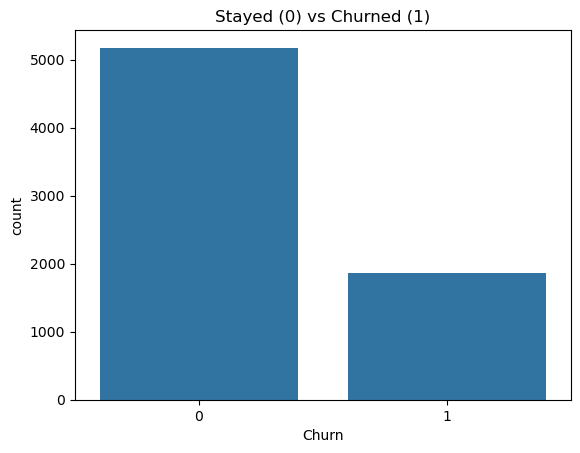

In [12]:
churn_rate = df["Churn"].mean()
print(f"Churn rate: {churn_rate:.1%}")

sns.countplot(x="Churn", data=df)
plt.title("Stayed (0) vs Churned (1)")
plt.show()

- About **26.5%** of customers (1,869 out of 7,043) left the company.
- The data is **imbalanced**: there are roughly 3 stayers for every churner.
- Accuracy alone would be misleading. A model that predicts "stay" for everyone would still be about 73% accurate. We will also use ROC-AUC, recall and precision.

### 6.2 Churn by Contract Type

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64


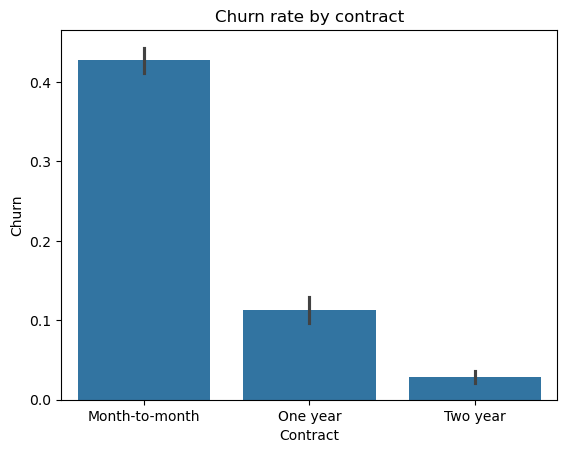

In [13]:
print(df.groupby("Contract")["Churn"].mean())

sns.barplot(x="Contract", y="Churn", data=df)
plt.title("Churn rate by contract")
plt.show()

- Month-to-month customers churn at **42.7%**.
- One-year contracts churn at **11.3%** and two-year contracts at only **2.8%**.
- Contract type shows the strongest effect of all features.
- Moving customers to longer contracts may be the most direct way to reduce churn.

## 6.3 Tenure vs Churn

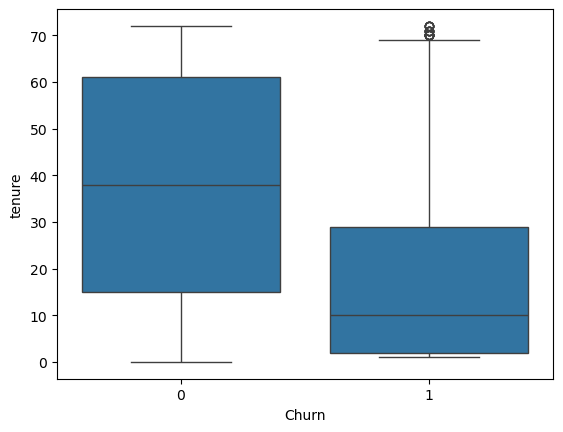

Churn
0    38.0
1    10.0
Name: tenure, dtype: float64

In [14]:
sns.boxplot(x="Churn", y="tenure", data=df)
plt.show()
df.groupby("Churn")["tenure"].median()

In [15]:
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                           labels=["0-12 m", "13-24 m", "25-48 m", "49-72 m"])
print(df.groupby("TenureGroup", observed=True)["Churn"].mean().round(3))

TenureGroup
0-12 m     0.474
13-24 m    0.287
25-48 m    0.204
49-72 m    0.095
Name: Churn, dtype: float64


- Customers who churned have a median tenure of only **10 months**, versus **38 months** for those who stayed.
- Most churn happens early: about 47% of customers in their first 12 months leave.
- Customers with more than 4 years of tenure churn at only about 10%.
- New customers need extra attention and support during their first year.

## 6.4 Churn by Internet Service


InternetService
DSL            0.189591
Fiber optic    0.418928
No             0.074050
Name: Churn, dtype: float64


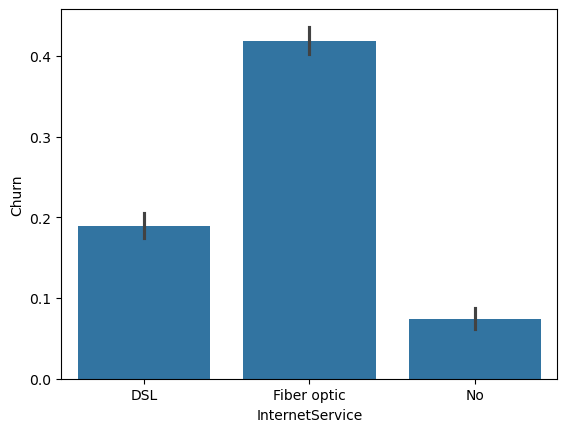

In [16]:
print(df.groupby("InternetService")["Churn"].mean())
sns.barplot(x="InternetService", y="Churn", data=df)
plt.show()

- **Fibre optic** customers churn at **41.9%**.
- DSL customers churn at **19.0%**, and customers with no internet service at only **7.4%**.
- Fibre customers pay the most but also leave the most. Price, service quality or competitor offers could be reasons and should be investigated. (This is an association, not proof of cause.)

In [17]:
print(df.groupby("InternetService")["MonthlyCharges"].mean().round(1))

InternetService
DSL            58.1
Fiber optic    91.5
No             21.1
Name: MonthlyCharges, dtype: float64


## 6.5 Churn by Payment Method

PaymentMethod
Electronic check             0.452854
Mailed check                 0.191067
Bank transfer (automatic)    0.167098
Credit card (automatic)      0.152431
Name: Churn, dtype: float64


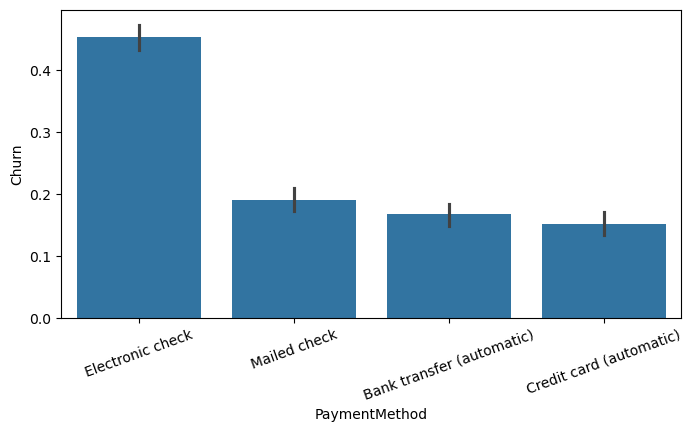

In [18]:
print(df.groupby("PaymentMethod")["Churn"].mean().sort_values(ascending=False))
plt.figure(figsize=(8,4))
sns.barplot(x="PaymentMethod", y="Churn", data=df)
plt.xticks(rotation=20)
plt.show()

- Customers paying by **electronic check** churn at **45.3%**.
- Automatic bank transfer (**16.7%**) and credit card (**15.2%**) are much lower.
-Customers on automatic payments look more loyal. Electronic check customers deserve extra attention.

## 6.6 Monthly Charges vs Churn

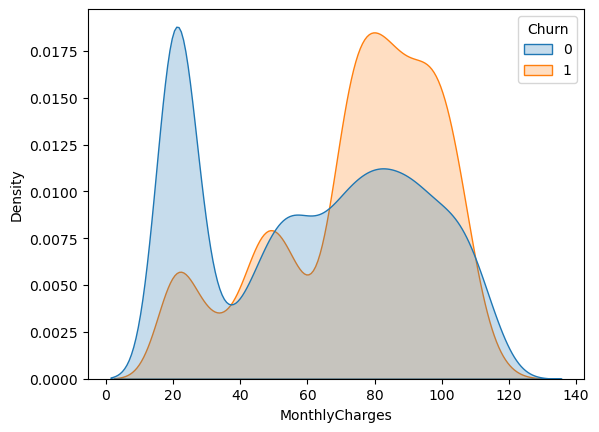

Churn
0    64.425
1    79.650
Name: MonthlyCharges, dtype: float64

In [19]:
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", common_norm=False, fill=True)
plt.show()
df.groupby("Churn")["MonthlyCharges"].median()

- Churned customers have a median monthly charge of **79.65**, compared with **64.43** for stayers.
- Customers with higher monthly bills are more likely to leave.
-TotalCharges` is lower for churners only because they stayed for a shorter time, not because they pay less per month.

## 6.7 Contract and Internet Service Together


InternetService    DSL  Fiber optic     No
Contract                                  
Month-to-month   0.322        0.546  0.189
One year         0.093        0.193  0.025
Two year         0.019        0.072  0.008


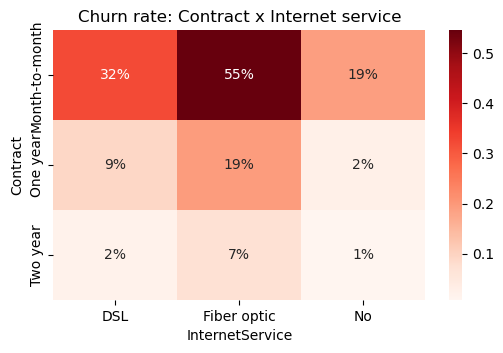

In [20]:
pivot = df.pivot_table(index="Contract", columns="InternetService",
                       values="Churn", aggfunc="mean")
print(pivot.round(3))

plt.figure(figsize=(6, 3.5))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Reds")
plt.title("Churn rate: Contract x Internet service")
plt.show()

- The highest-risk group is **month-to-month + fibre optic**, with **54.6%** churn.
- Two-year contracts stay below 8% churn for every internet type.
-Month-to-month fibre customers are the key risk segment, so retention offers should start there.

## 6.8 Other Factors


SeniorCitizen
SeniorCitizen
0    0.236
1    0.417
Name: Churn, dtype: float64

Partner
Partner
No     0.330
Yes    0.197
Name: Churn, dtype: float64

Dependents
Dependents
No     0.313
Yes    0.155
Name: Churn, dtype: float64

OnlineSecurity
OnlineSecurity
No                     0.418
No internet service    0.074
Yes                    0.146
Name: Churn, dtype: float64

TechSupport
TechSupport
No                     0.416
No internet service    0.074
Yes                    0.152
Name: Churn, dtype: float64

gender
gender
Female    0.269
Male      0.262
Name: Churn, dtype: float64


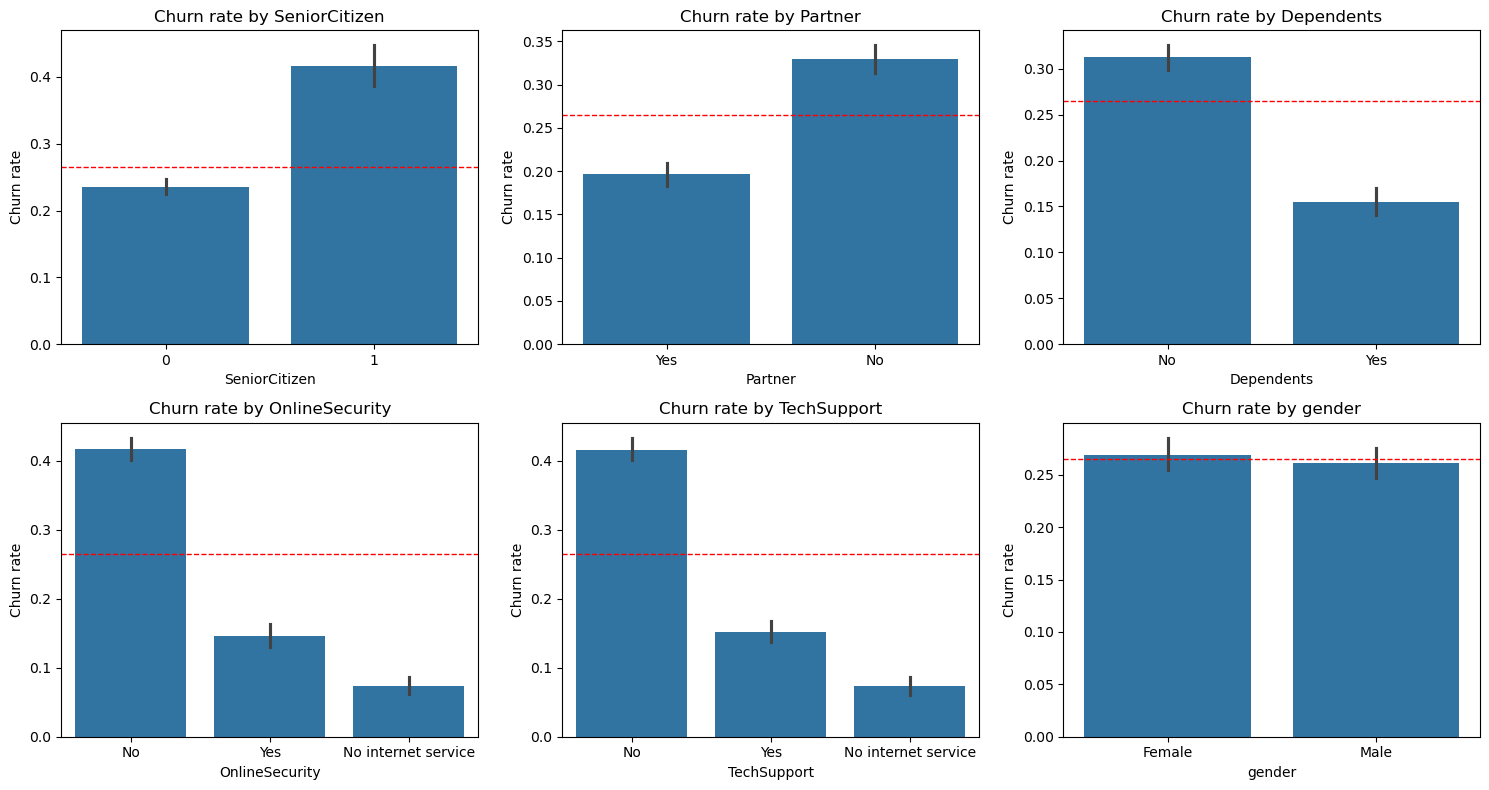

In [21]:
factors = ["SeniorCitizen", "Partner", "Dependents", "OnlineSecurity", "TechSupport", "gender"]

for col in factors:
    print(f"\n{col}")
    print(df.groupby(col)["Churn"].mean().round(3))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), factors):
    sns.barplot(x=col, y="Churn", data=df, ax=ax)
    ax.axhline(df["Churn"].mean(), color="red", ls="--", lw=1)   # overall churn rate
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate")
plt.tight_layout()
plt.show()

- Senior citizens churn at **41.7%**, compared with 23.6% for others.
- Customers with a partner or dependents churn less.
- Customers with Online Security or Tech Support churn at about **15%**, versus about **42%** for those without.
- **Gender** makes no real difference (26.9% vs 26.2%).

## 6.9 EDA Summary
1. About 26.5% of customers churn, and the data is imbalanced.
2. Month-to-month contracts have by far the highest churn (42.7%).
3. Most churn happens in the first 12 months.
4. Fibre optic and electronic check customers churn the most.
5. Security and tech support services are linked with much lower churn.

# 7. Feature Engineering
create two new features:
- **NumAddOns**: how many add-on services a customer has.
- **AvgMonthlySpend**: total paid divided by months with the company.

In [22]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
          "TechSupport", "StreamingTV", "StreamingMovies"]

df["NumAddOns"] = (df[addons] == "Yes").sum(axis=1)
df["AvgMonthlySpend"] = np.where(df["tenure"] > 0,
                                 df["TotalCharges"] / df["tenure"], 0)

df[["NumAddOns", "AvgMonthlySpend"]].describe()

,NumAddOns,AvgMonthlySpend
count,7043.000000,7043.000000
mean,2.037910,64.698218
std,1.847682,30.270670
min,0.000000,0.000000
25%,0.000000,35.649000
50%,2.000000,70.300000
75%,3.000000,90.174158
max,6.000000,121.400000


In [23]:
internet = df[df["InternetService"] != "No"]
print(internet.groupby("NumAddOns")["Churn"].agg(["mean", "size"]).round(3))

            mean  size
NumAddOns             
0          0.522   693
1          0.458   966
2          0.358  1033
3          0.274  1118
4          0.223   852
5          0.124   571
6          0.053   284


Among customers with internet, churn drops steadily as they use more add-on services (about 52% with none, 27% with three, 5% with all six). Add-ons look like a sign that a customer is settled with the company. This is an association, not proof that selling add-ons would reduce churn.


# 8. Data Preparation for Modelling
## 8.1 Train-Test Split
split first, then preprocess. The preprocessing is fitted on the training data only, so no information from the test set leaks into the model.

In [24]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn", "TenureGroup"], errors="ignore")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (5634, 21) | Test: (1409, 21)
Churn rate train: 0.265 | test: 0.265


### 8.2 Preprocessing Pipeline
- Numeric columns are scaled with `StandardScaler`.
- Text columns are one-hot encoded with `OneHotEncoder`.
Both steps are wrapped in a `ColumnTransformer`, so the same steps are applied to train and test automatically.

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_features = X.select_dtypes(include="number").columns.tolist()
cat_features = X.select_dtypes(include="object").columns.tolist()

print("Numeric:", num_features)
print("Categorical:", cat_features)

def make_pre(scale=True):
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ])

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'NumAddOns', 'AvgMonthlySpend']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 9. Model Building
Accuracy is misleading here, since predicting "stay" for everyone is already about 73% accurate. We compare models using **5-fold cross-validation** on the training set and focus on **ROC-AUC** (how well customers are ranked by risk), **recall** (how many churners we catch) and **precision**. Models that support it use `class_weight="balanced"` to handle the imbalance.

## 9.1 Baseline: Logistic Regression

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

log_reg = Pipeline([
    ("pre", make_pre(scale=True)),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))
])

r = cross_validate(log_reg, X_train, y_train, cv=skf,
                   scoring=["roc_auc", "recall", "precision", "f1"])
for m in ["roc_auc", "recall", "precision", "f1"]:
    print(m, round(r["test_" + m].mean(), 3))

roc_auc 0.846
recall 0.8
precision 0.517
f1 0.628


- ROC-AUC is **0.846**, so the model ranks churners above stayers well.
- Recall is **0.80**: it catches most churners, but precision is **0.52**, so about half of the customers flagged as churn would have stayed.
- This is our baseline. Other models must beat it.

### 9.2 Define the Models

In [27]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": log_reg,
    "Decision Tree": Pipeline([
        ("pre", make_pre(False)),
        ("clf", DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42))]),
    "Random Forest": Pipeline([
        ("pre", make_pre(False)),
        ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                       class_weight="balanced", random_state=42, n_jobs=-1))]),
    "Gradient Boosting": Pipeline([
        ("pre", make_pre(False)),
        ("clf", GradientBoostingClassifier(random_state=42))]),
}

print(list(models.keys()))

['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']


### 9.3 Cross-Validation Comparison
compare all four models using 5-fold stratified cross-validation on the training set, and look at ROC-AUC, recall, precision and F1.

In [28]:
rows = []
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=skf, n_jobs=-1,
                       scoring=["roc_auc", "recall", "precision", "f1"])
    rows.append({"Model": name,
                 "ROC-AUC": r["test_roc_auc"].mean(),
                 "Recall": r["test_recall"].mean(),
                 "Precision": r["test_precision"].mean(),
                 "F1": r["test_f1"].mean()})

cv_results = pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False)
cv_results.round(3)

,Model,ROC-AUC,Recall,Precision,F1
3,Gradient Boosting,0.848,0.533,0.665,0.592
0,Logistic Regression,0.846,0.800,0.517,0.628
2,Random Forest,0.844,0.716,0.557,0.626
1,Decision Tree,0.828,0.769,0.513,0.615


###  Model Comparison
- All four models have a similar ROC-AUC (**0.83 to 0.85**). Gradient Boosting (0.848), Logistic Regression (0.846) and Random Forest (0.844) are practically tied.
- The Decision Tree is weakest (0.828).
- Recall differs a lot (0.53 to 0.80), but that is mostly because of the default 0.5 cut-off and class weights. Gradient Boosting has no class weights, so it flags fewer customers: higher precision, lower recall. We handle this properly later when we choose a threshold.
- We pick **Gradient Boosting** and **Logistic Regression** for tuning: one is the best score, the other is simple and easy to explain.

## 10. Hyperparameter Tuning
We tune the two chosen models with `GridSearchCV` on the **training data only**, using 5-fold cross-validation and ROC-AUC as the score. We tune Logistic Regression (simple, easy to explain) and Gradient Boosting (best score).

## 10.1 Logistic Regression

In [29]:
from sklearn.model_selection import GridSearchCV

param_grid_lr = {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}

gs_lr = GridSearchCV(models["Logistic Regression"], param_grid_lr,
                     cv=skf, scoring="roc_auc", n_jobs=-1)
gs_lr.fit(X_train, y_train)

print("Best params:", gs_lr.best_params_)
print("Best CV AUC: %.4f" % gs_lr.best_score_)

Best params: {'clf__C': 3}
Best CV AUC: 0.8457


## 10.2 Gradient Boosting

In [30]:
param_grid_gb = {
    "clf__n_estimators": [100, 200],
    "clf__learning_rate": [0.03, 0.05, 0.1],
    "clf__max_depth": [2, 3],
}

gs_gb = GridSearchCV(models["Gradient Boosting"], param_grid_gb,
                     cv=skf, scoring="roc_auc", n_jobs=-1)
gs_gb.fit(X_train, y_train)

print("Best params:", gs_gb.best_params_)
print("Best CV AUC: %.4f" % gs_gb.best_score_)

Best params: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 100}
Best CV AUC: 0.8497


## 11. Final Evaluation on the Test Set
The test set (1,409 customers) was not used for training, cross-validation or tuning. It gives an honest estimate of performance on new customers.

### 11.1 Metrics on the Test Set

In [31]:
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report, roc_curve

candidates = {
    "Logistic Regression (tuned)": gs_lr.best_estimator_,
    "Gradient Boosting (tuned)": gs_gb.best_estimator_,
}

rows, probs = [], {}
for name, m in candidates.items():
    p = m.predict_proba(X_test)[:, 1]
    probs[name] = p
    pred = (p >= 0.5).astype(int)
    rep = classification_report(y_test, pred, output_dict=True)
    rows.append({"Model": name,
                 "ROC-AUC": roc_auc_score(y_test, p),
                 "PR-AUC": average_precision_score(y_test, p),
                 "Accuracy": rep["accuracy"],
                 "Recall (churn)": rep["1"]["recall"],
                 "Precision (churn)": rep["1"]["precision"],
                 "F1 (churn)": rep["1"]["f1-score"]})

test_results = pd.DataFrame(rows)
test_results.round(3)

,Model,ROC-AUC,PR-AUC,Accuracy,Recall (churn),Precision (churn),F1 (churn)
0,Logistic Regression (tuned),0.841,0.630,0.740,0.786,0.506,0.616
1,Gradient Boosting (tuned),0.845,0.659,0.801,0.500,0.668,0.572


 On unseen data, tuned Gradient Boosting reaches a ROC-AUC of 0.845 and Logistic Regression 0.841, practically the same and close to the cross-validation scores (about 0.85). So the models are stable and not overfitted. We choose Gradient Boosting for its slightly higher AUC and PR-AUC. Logistic Regression would be almost as good and easier to explain.

### 11.2 ROC Curve
The ROC curve shows how well each model separates churners from stayers at every possible threshold. The closer the curve is to the top-left corner, the better. The dashed diagonal line is a random guess (AUC = 0.5).

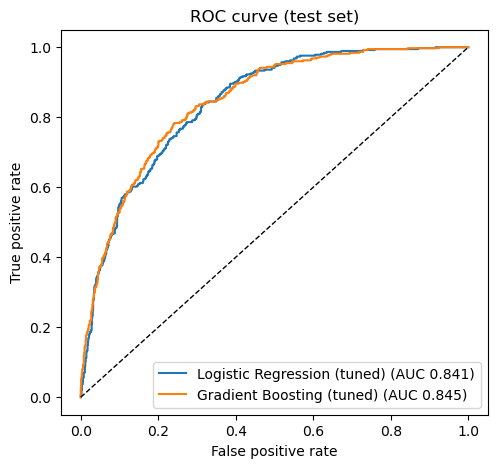

In [32]:
plt.figure(figsize=(5.5, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve (test set)")
plt.legend(loc="lower right")
plt.show()

- Both curves are well above the diagonal, so both models rank customers by churn risk much better than chance.
- The two curves are almost on top of each other (Gradient Boosting AUC **0.845**, Logistic Regression **0.841**), so the models are practically equal.
- These test scores are close to the cross-validation scores (about 0.85), which shows the models are stable and not overfitted.
- We choose Gradient Boosting for its slightly higher AUC. Logistic Regression would be almost as good and is easier to explain.

### 11.3 Choosing the Decision Threshold
The default cut-off of 0.5 is not always best. If missing a churner costs more than contacting a loyal customer, we should flag customers at a lower probability. The table shows precision and recall at different thresholds for Gradient Boosting.

In [33]:
from sklearn.metrics import confusion_matrix, f1_score

p = probs["Gradient Boosting (tuned)"]
tbl = []
for t in [0.30, 0.35, 0.40, 0.45, 0.50, 0.60]:
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    tbl.append({"Threshold": t, "Flagged customers": int(pred.sum()),
                "Churners caught": int(tp), "Recall": tp/(tp+fn),
                "Precision": tp/(tp+fp), "F1": f1_score(y_test, pred)})
pd.DataFrame(tbl).round(3)

,Threshold,Flagged customers,Churners caught,Recall,Precision,F1
0,0.30,529,287,0.767,0.543,0.636
1,0.35,465,265,0.709,0.570,0.632
2,0.40,399,240,0.642,0.602,0.621
3,0.45,334,215,0.575,0.644,0.607
4,0.50,280,187,0.500,0.668,0.572
5,0.60,176,130,0.348,0.739,0.473


At threshold **0.40** the model flags 399 of 1,409 customers (28%), catches **240 of the 374 churners (64% recall)** and keeps precision at **60%**. Compared with 0.5, we find 53 more churners at the cost of about 120 extra flagged customers. We choose **0.40**, because losing a customer usually costs far more than a retention offer.

## 11.4 Confusion Matrix (threshold 0.40)

              precision    recall  f1-score   support

      Stayed       0.87      0.85      0.86      1035
     Churned       0.60      0.64      0.62       374

    accuracy                           0.79      1409
   macro avg       0.73      0.74      0.74      1409
weighted avg       0.80      0.79      0.79      1409



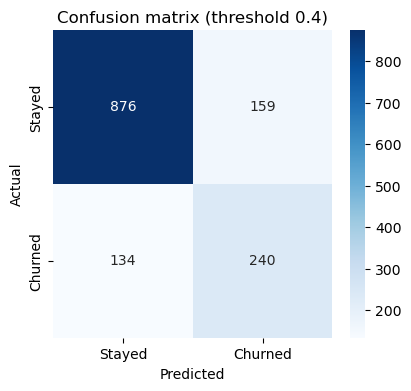

In [34]:
THRESHOLD = 0.40
pred = (p >= THRESHOLD).astype(int)
print(classification_report(y_test, pred, target_names=["Stayed", "Churned"]))

cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"Confusion matrix (threshold {THRESHOLD})")
plt.show()

The model correctly catches **240** churners and misses 134. It wrongly flags 159 loyal customers and correctly leaves 876 alone. We accept these false alarms to catch more real churners.

# 12. Feature Importance: What Drives Churn?
use **permutation importance**. Each original column is shuffled in the test set, one at a time. The bigger the drop in ROC-AUC, the more the model relies on that column. It works on the original columns, so one-hot encoded columns are not split into many pieces.

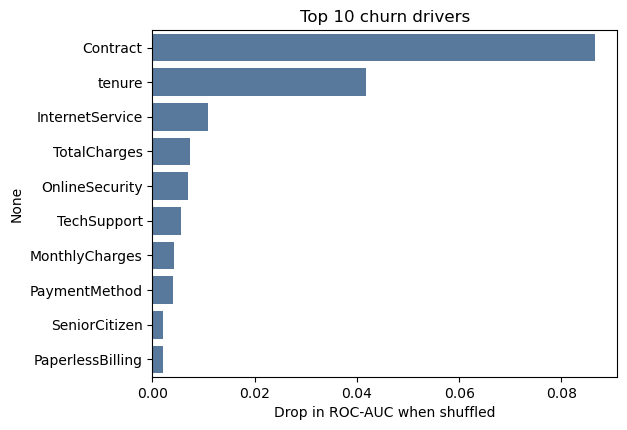

Contract            0.0866
tenure              0.0419
InternetService     0.0109
TotalCharges        0.0073
OnlineSecurity      0.0069
TechSupport         0.0055
MonthlyCharges      0.0043
PaymentMethod       0.0040
SeniorCitizen       0.0021
PaperlessBilling    0.0021
dtype: float64

In [35]:
from sklearn.inspection import permutation_importance

best_model = candidates["Gradient Boosting (tuned)"]

pi = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                            n_repeats=15, random_state=42, n_jobs=-1)

imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
top = imp.head(10)

plt.figure(figsize=(6, 4.5))
sns.barplot(x=top.values, y=top.index, color="#4C78A8")
plt.xlabel("Drop in ROC-AUC when shuffled")
plt.title("Top 10 churn drivers")
plt.show()

top.round(4)

- **Contract** is by far the most important driver, followed by **tenure**.
- Then come InternetService, TotalCharges, OnlineSecurity, TechSupport and MonthlyCharges.
- This matches the EDA, so the model is learning sensible patterns.
- Gender, phone service and similar columns add almost nothing.

**Insight:** Churn depends mainly on how long and under what contract a customer has been with the company, and on the internet and support services they have.

## 13. Business Impact
A model is only useful if acting on it saves money. The numbers below are **assumptions**. The company should replace them with its real values.
- `OFFER_COST`: cost of one retention offer, per customer contacted
- `CUSTOMER_VALUE`: value of keeping one customer who would have left
- `SAVE_RATE`: share of contacted churners who stay because of the offer

rank test customers by predicted risk and contact only the top X%.

## 13.1 Targeting the Highest-Risk Customers

In [36]:
OFFER_COST     = 20     # cost of one retention offer
CUSTOMER_VALUE = 500    # value of keeping one churner
SAVE_RATE      = 0.30   # 30% of contacted churners are saved

p = probs["Gradient Boosting (tuned)"]
res = (pd.DataFrame({"p": p, "churn": y_test.values})
         .sort_values("p", ascending=False).reset_index(drop=True))

rows = []
for frac in [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 1.00]:
    n = int(len(res) * frac)
    top_n = res.head(n)
    caught = top_n["churn"].sum()
    profit = caught * SAVE_RATE * CUSTOMER_VALUE - n * OFFER_COST
    rows.append({"Contact top %": f"{frac:.0%}",
                 "Customers contacted": n,
                 "Churners reached": int(caught),
                 "Share of all churners": caught / res["churn"].sum(),
                 "Lift vs random": (caught / n) / res["churn"].mean(),
                 "Net benefit": profit})

impact = pd.DataFrame(rows)
impact.round(2)

,Contact top %,Customers contacted,Churners reached,Share of all churners,Lift vs random,Net benefit
0,5%,70,57,0.15,3.07,7150.0
1,10%,140,106,0.28,2.85,13100.0
2,20%,281,188,0.50,2.52,22580.0
3,30%,422,249,0.67,2.22,28910.0
4,40%,563,294,0.79,1.97,32840.0
5,50%,704,321,0.86,1.72,34070.0
6,100%,1409,374,1.00,1.00,27920.0


- Contacting the **top 20%** highest-risk customers (281 people) reaches **188 of the 374 churners, about half**. That is **2.5 times better than random**.
- Contacting the **top 40%** reaches **79%** of churners.
- The net benefit is highest when we contact about the top **40 to 50%** of customers (about 33,000 to 34,000).
- **Contacting everyone** (27,920) is worse than targeting, because most offers go to loyal customers who were not going to leave.
- The best cut-off depends on the real offer cost and customer value, so the company should rerun this table with its own numbers.

## 13.2 Net Benefit by Share of Customers Contacted
This chart shows the money gained (savings minus offer costs) for each share of customers contacted, starting with the highest-risk ones.

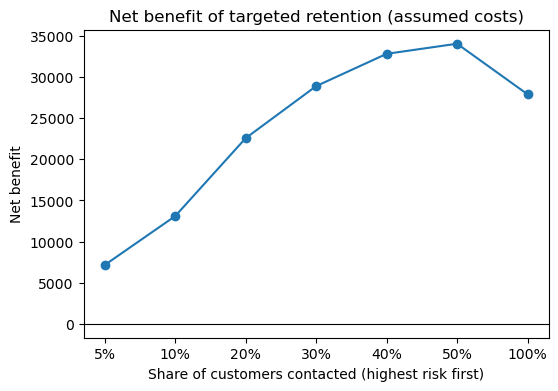

In [37]:
plt.figure(figsize=(6, 4))
plt.plot(impact["Contact top %"], impact["Net benefit"], marker="o")
plt.xlabel("Share of customers contacted (highest risk first)")
plt.ylabel("Net benefit")
plt.title("Net benefit of targeted retention (assumed costs)")
plt.axhline(0, color="k", lw=0.8)
plt.show()

- The net benefit rises steadily as we contact more of the highest-risk customers, and **peaks at about the top 50%** (about 34,000).
- After that the curve **falls**: contacting all customers gives a lower benefit (27,920), because most offers go to loyal customers who were not going to leave.
- The curve is fairly flat between 40% and 50%, so contacting the top **30 to 40%** gets almost the same benefit at a lower cost.
- These results depend on the **assumed** offer cost, customer value and save rate. The company should rerun the analysis with its real numbers.

# 14. Conclusion and Recommendations
This project studied why customers leave a telecom company and built a model to find at-risk customers early. The findings below come from the EDA, the model results and the business-impact analysis.

## 14.1 Key Findings
1. **26.5%** of customers churn, mostly **early** (about 47% churn in the first 12 months) and mostly on **month-to-month** contracts (43%).
2. The highest-risk segment is **month-to-month + fibre optic (55% churn)**. Customers paying by **electronic check** (45%) also churn a lot.
3. Customers with **online security, tech support** and more add-on services churn far less.
4. The best model, **Gradient Boosting**, ranks customers well (**ROC-AUC about 0.85** on unseen data). At threshold 0.40 it finds about **64% of churners with 60% precision**.
5. The top 20% riskiest customers hold about **half of all churners**, which is **2.5 times better than random**.
6. The most important churn drivers are **contract type, tenure, internet service and support services**.

## 14.2 Recommendations

| Priority | Action | Evidence |
|---|---|---|
| 1 | Offer discounts or perks to move month-to-month customers to 1 or 2-year contracts | 42.7% churn vs 11.3% and 2.8% |
| 2 | Run strong onboarding and check-in calls in the first 12 months | 47% churn in year one, about 10% after 4 years |
| 3 | Investigate fibre-optic quality, pricing and competitor offers | 41.9% churn vs 19.0% for DSL |
| 4 | Encourage automatic payments and review the electronic-check experience | 45% vs 15 to 17% churn |
| 5 | Bundle online security and tech support for new internet customers | About 15% churn with them vs 42% without |
| 6 | Use the model every month and contact the top 20 to 40% risk customers with a retention offer | Reaches 50 to 79% of churners |

## 14.3 Limitations
- The data is a **single snapshot**. We do not know when customers left or what competitors offered.
- The patterns are **associations, not proven causes**. Offers should be tested on a small group first (an A/B test).
- The numbers in Section 13 are **assumptions**. The company should replace them with real costs and customer values.
- Model quality stops at an AUC of about 0.85. More data (usage, complaints, call-centre contacts) would help more than a more complex algorithm.

## 15. Save the Model
save the final model, which includes the preprocessing steps, together with the chosen threshold. We then test that it loads and gives the same predictions.

In [38]:
import joblib

final_model = gs_gb.best_estimator_          # pipeline: preprocessing + Gradient Boosting
THRESHOLD = 0.40

joblib.dump({"model": final_model,
             "threshold": THRESHOLD,
             "columns": X.columns.tolist()},
            "churn_model.pkl")

print("Saved: churn_model.pkl")

Saved: churn_model.pkl


### 15.2 Load and Verify

In [39]:
bundle = joblib.load("churn_model.pkl")

p_loaded = bundle["model"].predict_proba(X_test)[:, 1]
print("ROC-AUC of loaded model: %.3f" % roc_auc_score(y_test, p_loaded))
print("Threshold:", bundle["threshold"])

ROC-AUC of loaded model: 0.845
Threshold: 0.4


### 15.3 Prediction Function
This function takes new customers (same columns as the original data) and returns the churn probability and an at-risk flag.

In [40]:
def predict_churn(new_df):
    """new_df: rows with the original columns, without Churn and customerID.
    SeniorCitizen stays 0/1. NumAddOns and AvgMonthlySpend are added here."""
    bundle = joblib.load("churn_model.pkl")
    d = new_df.copy()
    d["NumAddOns"] = (d[addons] == "Yes").sum(axis=1)
    d["AvgMonthlySpend"] = np.where(d["tenure"] > 0, d["TotalCharges"] / d["tenure"], 0)
    proba = bundle["model"].predict_proba(d[bundle["columns"]])[:, 1]
    return pd.DataFrame({"churn_probability": proba.round(3),
                         "at_risk": proba >= bundle["threshold"]},
                        index=new_df.index)

# Test on 8 customers from the test set
predict_churn(X_test.head(8)).assign(actual_churn=y_test.head(8).values)

,churn_probability,at_risk,actual_churn
437,0.044,False,0
2280,0.757,True,0
2235,0.062,False,0
4460,0.355,False,0
3761,0.036,False,0
5748,0.517,True,0
3568,0.404,True,0
2976,0.117,False,0


**Observation:** The function returns a churn probability and an at-risk flag for each customer. In this small sample of 8 customers, none actually churned, but 3 were flagged as at risk. These are false alarms, which is expected because precision at threshold 0.40 is about 60%. We accept some false alarms in order to catch more real churners (recall 64%), because a retention offer costs far less than losing a customer. A sample of 8 is too small to judge the model, so the test-set results in Section 11 are the proper evaluation.

**Summary:** The final Gradient Boosting pipeline and the chosen threshold (0.40) are saved in `churn_model.pkl`. The loaded model reproduces the test ROC-AUC of 0.845, so it works correctly. `predict_churn()` can score new customers and flag those at risk.